# Detecção de Fraudes em Cartões de Crédito com Machine Learning e XAI
### Modelagem Preditiva em Dados Altamente Desbalanceados & Explicabilidade com SHAP

---

## 1. Contexto de Negócio e o Desafio do Desbalanceamento

No ecossistema financeiro e de pagamentos digitais, o crime cibernético e a fraude com cartões de crédito representam perdas multibilionárias todos os anos. A construção de sistemas automatizados de antifraude é vital para proteger clientes e evitar prejuízos diretos às instituições.

Entretanto, este domínio apresenta um desafio estatístico severo: o **desbalanceamento extremo de classes**:
* Cerca de **99,8%** das transações são legítimas (normais);
* Apenas **0,17%** representam transações fraudulentas.

### O Paradoxo da Acurácia ("Accuracy Paradox")
Se construirmos um modelo ingênuo ("dummy") que prevê sempre que a transação é **legítima**:
* A **acurácia** obtida será de aproximadamente **99,83%**;
* Contudo, o modelo deixará passar **100% das fraudes** (**Recall = 0%**), sendo completamente inútil para o negócio.

Por essa razão, o sucesso do projeto é mensurado com métricas específicas para dados assimétricos:
* **Recall (Sensibilidade / Taxa de Verdadeiros Positivos)**: Proporção de fraudes reais que o modelo detectou. Minimizar os **Falsos Negativos** (fraudes não detectadas) é a meta prioritária, pois cada fraude ignorada gera perda financeira imediata e contestações (*chargebacks*).
* **Precision (Precisão)**: Proporção de alertas gerados pelo modelo que são de fato fraudes. Controla a taxa de **Falsos Positivos** (atrito com clientes idôneos e bloqueios desnecessários).
* **F1-Score**: Média harmônica entre Precisão e Recall.
* **PR-AUC (Precision-Recall AUC / Average Precision)**: A métrica padrão ouro para problemas altamente desbalanceados, refletindo a qualidade do ranking de probabilidades independentemente do limiar.
* **ROC-AUC**: Capacidade geral do modelo de distinguir entre as classes ao longo de todos os limiares.

---


## 2. Configuração do Ambiente e Importação de Bibliotecas

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelagem e Pré-processamento
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Métodos de Reamostragem para Desbalanceamento
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# Métricas de Avaliação
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score
)

# Interpretabilidade / Explainable AI (XAI)
import shap

# Configurações visuais
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


## 3. Carregamento dos Dados e Exploração Inicial

A base de dados é composta por transações financeiras realizadas em cartões de crédito europeus durante dois dias de setembro de 2013. Para proteger a confidencialidade e dados pessoais dos portadores dos cartões:
* As variáveis `V1` a `V28` são componentes principais resultantes de uma transformação **PCA (Principal Component Analysis)**;
* As variáveis originais não transformadas são:
  - `Time`: Segundos decorridos entre cada transação e a primeira transação registrada;
  - `Amount`: Valor monetário da transação;
  - `Class`: Alvo da classificação, onde `1` indica Fraude e `0` indica Transação Legítima.

Conforme solicitado, o dataset é lido a partir do link oficial:
`http://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv`


In [2]:
DATASET_URL = "http://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

print(f"Carregando dataset diretamente a partir da URL oficial: {DATASET_URL}")
try:
    df = pd.read_csv(DATASET_URL)
    print("Dataset baixado e carregado com sucesso via URL!")
except Exception as e:
    print(f"Falha de conexão com a URL ({e}). Utilizando cópia local de contingência.")
    df = pd.read_csv("base/creditcard.csv")

print(f"Dimensões da base: {df.shape[0]:,} linhas x {df.shape[1]} colunas.")
df.head()


Carregando dataset diretamente a partir da URL oficial: http://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv


Dataset baixado e carregado com sucesso via URL!
Dimensões da base: 284,807 linhas x 31 colunas.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Inspeção de integridade dos dados
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()

print(f"Valores nulos (Missing Values): {missing_count}")
print(f"Registros duplicados: {duplicate_count:,}")

# Remoção de duplicatas para assegurar a idoneidade da avaliação
if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"-> Duplicatas removidas. Tamanho final da base: {df.shape[0]:,} registros.")


Valores nulos (Missing Values): 0
Registros duplicados: 1,081


-> Duplicatas removidas. Tamanho final da base: 283,726 registros.


## 4. Análise Exploratória e Diagnóstico do Desbalanceamento

,Quantidade,Proporção (%)
Legítima (0),283253,99.83329
Fraude (1),473,0.16671


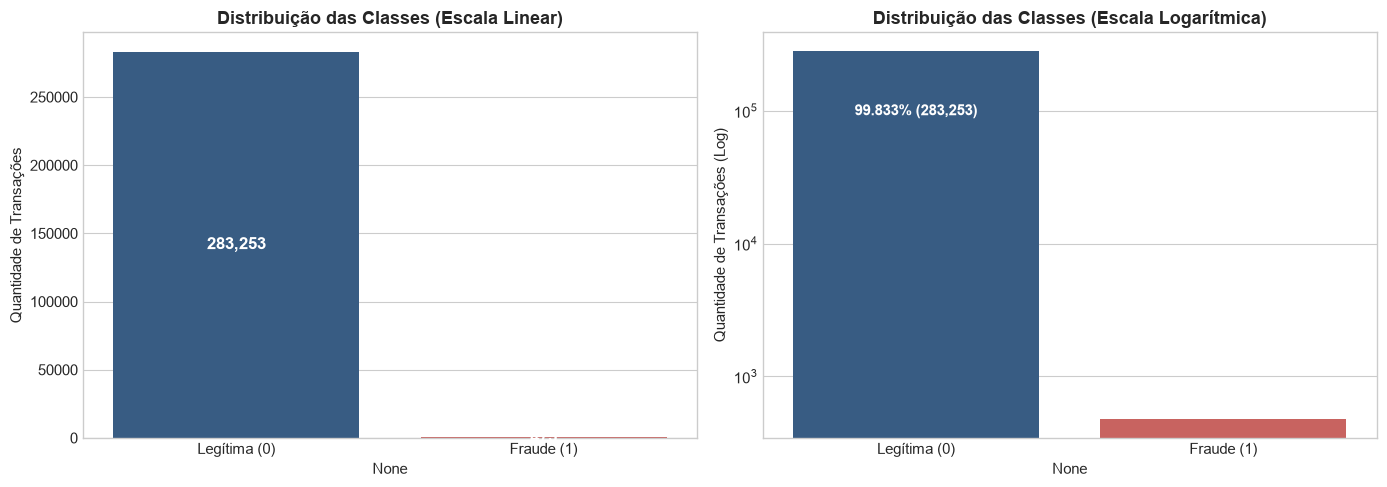

In [4]:
# Proporção e distribuição das classes
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100

summary_class = pd.DataFrame({
    'Quantidade': class_counts,
    'Proporção (%)': class_pct
})
summary_class.index = ['Legítima (0)', 'Fraude (1)']
display(summary_class)

# Gráfico da distribuição das classes (Escala linear vs logarítmica)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Escala linear
sns.barplot(x=summary_class.index, y='Quantidade', data=summary_class, palette=['#2b5c8f', '#d9534f'], ax=axes[0])
axes[0].set_title("Distribuição das Classes (Escala Linear)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Quantidade de Transações")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Escala logarítmica
sns.barplot(x=summary_class.index, y='Quantidade', data=summary_class, palette=['#2b5c8f', '#d9534f'], ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title("Distribuição das Classes (Escala Logarítmica)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Quantidade de Transações (Log)")
for p in axes[1].patches:
    pct = (p.get_height() / df.shape[0]) * 100
    axes[1].annotate(f"{pct:.3f}% ({int(p.get_height()):,})", 
                     (p.get_x() + p.get_width() / 2., p.get_height() * 0.35),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


### Análise de Valores Transacionados (`Amount`) por Classe

,Legítimas (0),Fraudes (1)
count,283253.00,473.00
mean,88.41,123.87
std,250.38,260.21
min,0.00,0.00
25%,5.67,1.00
50%,22.00,9.82
75%,77.46,105.89
max,25691.16,2125.87


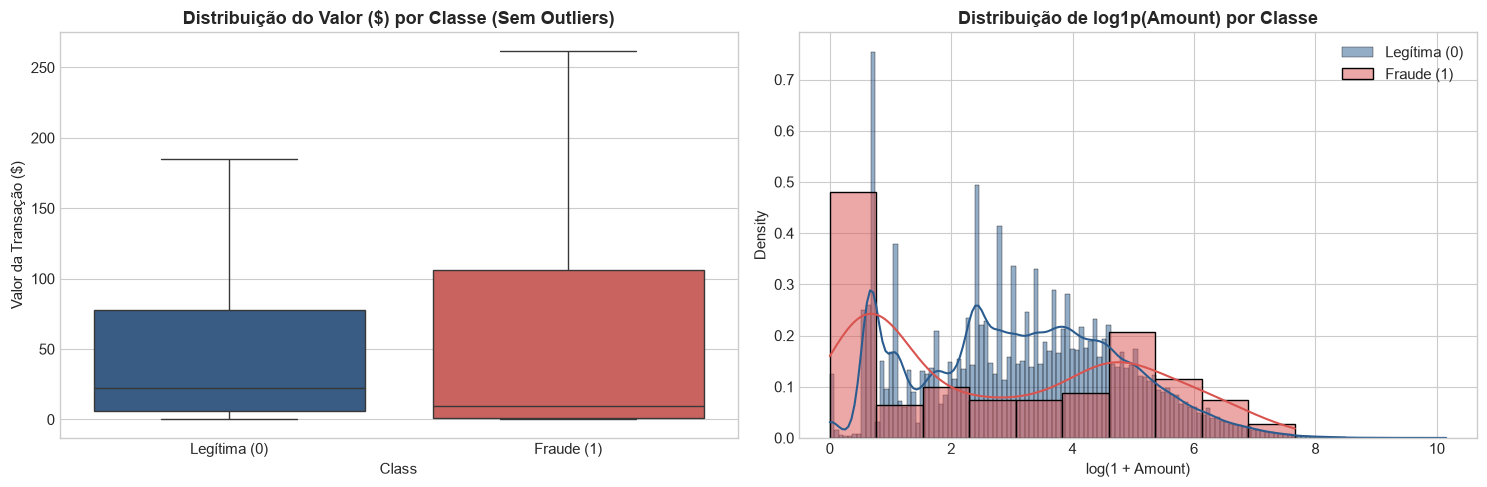

In [5]:
# Estatísticas descritivas de Amount separadas por classe
legitimas = df[df['Class'] == 0]['Amount']
fraudes = df[df['Class'] == 1]['Amount']

desc_amount = pd.DataFrame({
    'Legítimas (0)': legitimas.describe(),
    'Fraudes (1)': fraudes.describe()
})
display(desc_amount.round(2))

# Visualização de Amount
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x='Class', y='Amount', data=df, palette=['#2b5c8f', '#d9534f'], showfliers=False, ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Legítima (0)', 'Fraude (1)'])
axes[0].set_title("Distribuição do Valor ($) por Classe (Sem Outliers)", fontweight='bold')
axes[0].set_ylabel("Valor da Transação ($)")

# Histograma com KDE do log1p(Amount)
sns.histplot(np.log1p(legitimas), color='#2b5c8f', label='Legítima (0)', kde=True, stat="density", ax=axes[1], alpha=0.5)
sns.histplot(np.log1p(fraudes), color='#d9534f', label='Fraude (1)', kde=True, stat="density", ax=axes[1], alpha=0.5)
axes[1].set_title("Distribuição de log1p(Amount) por Classe", fontweight='bold')
axes[1].set_xlabel("log(1 + Amount)")
axes[1].legend()

plt.tight_layout()
plt.show()


### Análise de Correlação das Variáveis PCA com a Fraude

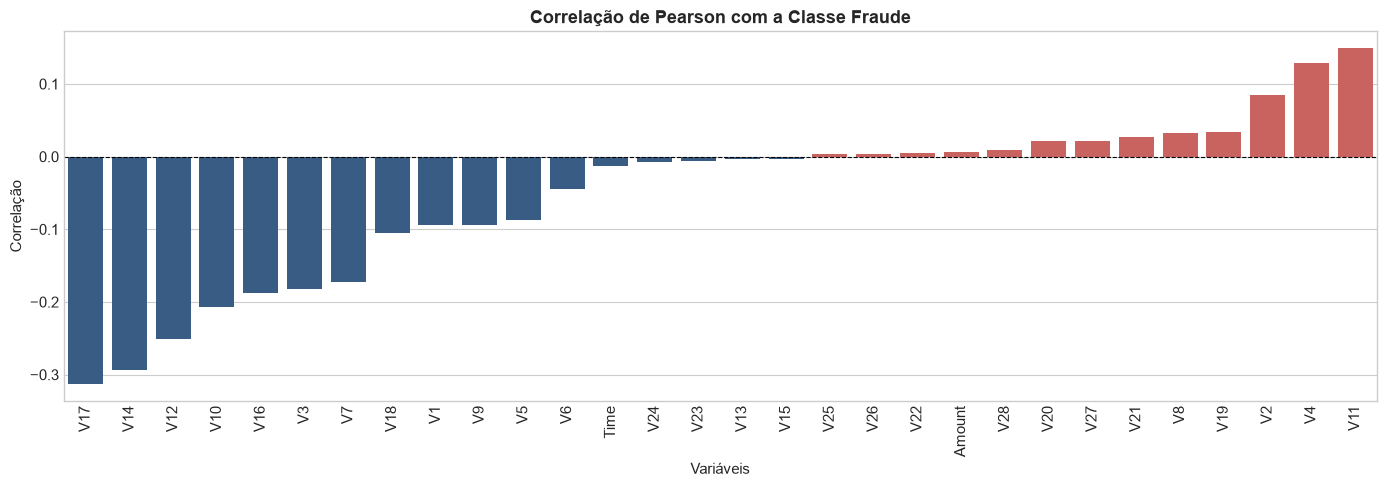

Top 5 variáveis com maior correlação negativa: {'V17': -0.313, 'V14': -0.293, 'V12': -0.251, 'V10': -0.207, 'V16': -0.187}
Top 5 variáveis com maior correlação positiva: {'V8': 0.033, 'V19': 0.034, 'V2': 0.085, 'V4': 0.129, 'V11': 0.149}


In [6]:
correlations = df.corr()['Class'].drop('Class').sort_values()

plt.figure(figsize=(14, 5))
colors = ['#d9534f' if c > 0 else '#2b5c8f' for c in correlations]
sns.barplot(x=correlations.index, y=correlations.values, palette=colors)
plt.title("Correlação de Pearson com a Classe Fraude", fontsize=13, fontweight='bold')
plt.xlabel("Variáveis")
plt.ylabel("Correlação")
plt.xticks(rotation=90)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.tight_layout()
plt.show()

print("Top 5 variáveis com maior correlação negativa:", correlations.head(5).round(3).to_dict())
print("Top 5 variáveis com maior correlação positiva:", correlations.tail(5).round(3).to_dict())


## 5. Pré-processamento e Engenharia de Atributos

Seguindo as orientações da Expert e as melhores práticas de Machine Learning:
1. **Engenharia de Atributos (`log_amount`)**:
   Aplicamos a transformação logarítmica $\log(1 + \text{Amount})$ com `np.log1p` para amenizar a forte assimetria positiva do valor monetário.
2. **Padronização com `StandardScaler`**:
   Como as variáveis `V1` a `V28` já estão padronizadas pelo PCA, aplicamos o `StandardScaler` sobre `Time` e a nova variável `log_amount`, colocando todas as features na mesma escala.
3. **Divisão Estratificada Treino-Teste (`stratify=y`)**:
   Utilizamos `test_size=0.20` e `stratify=y` para garantir que a taxa de fraudes permaneça rigorosamente a mesma em ambos os conjuntos.


In [7]:
df_prep = df.copy()

# 1. Criação do log do valor
df_prep['log_amount'] = np.log1p(df_prep['Amount'])

# 2. Padronização com StandardScaler
scaler_time = StandardScaler()
scaler_amount = StandardScaler()

df_prep['scaled_time'] = scaler_time.fit_transform(df_prep[['Time']])
df_prep['scaled_amount'] = scaler_amount.fit_transform(df_prep[['log_amount']])

# Separação de X e y (removendo colunas brutas Time e Amount, e intermediária log_amount)
feature_cols = [c for c in df_prep.columns if c not in ['Class', 'Time', 'Amount', 'log_amount']]
X = df_prep[feature_cols]
y = df_prep['Class']

print(f"Número de features utilizadas: {X.shape[1]}")
print(f"Features: {list(X.columns)}")


Número de features utilizadas: 30
Features: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'scaled_time', 'scaled_amount']


In [8]:
# 3. Divisão Estratificada de Treino e Teste (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Conjunto de Treino: {X_train.shape[0]:,} amostras | Fraudes: {y_train.sum()} ({y_train.mean()*100:.3f}%)")
print(f"Conjunto de Teste:  {X_test.shape[0]:,} amostras  | Fraudes: {y_test.sum()} ({y_test.mean()*100:.3f}%)")


Conjunto de Treino: 226,980 amostras | Fraudes: 378 (0.167%)
Conjunto de Teste:  56,746 amostras  | Fraudes: 95 (0.167%)


## 6. Treinamento e Comparação de Modelos

Avaliamos 6 combinações de modelos e estratégias de desbalanceamento:
1. **Regressão Logística (Baseline da Expert)** com penalização de pesos (`class_weight='balanced'`);
2. **Regressão Logística com Undersampling (`RandomUnderSampler`)** no conjunto de treino;
3. **Regressão Logística com Oversampling (`SMOTE`)** no conjunto de treino;
4. **Random Forest com `class_weight='balanced'`**;
5. **XGBoost com `scale_pos_weight`** ajustado para a razão entre classes normais e fraudulentas;
6. **Random Forest com SMOTE** via Pipeline.

> [!IMPORTANT]
> O uso de `ImbPipeline` garante que as técnicas de reamostragem (Undersampling e SMOTE) sejam aplicadas **apenas nas etapas de ajuste do treino**, prevenindo vazamento de dados (*data leakage*) para o conjunto de teste.


In [9]:
results = []
models_dict = {}

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, strategy_desc=""):
    print(f"--> Treinando {name} com {strategy_desc}...")
    model.fit(X_tr, y_tr)
    
    # Predições de classe e probabilidades
    y_pred = model.predict(X_te)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_te)[:, 1]
    else:
        y_prob = model.decision_function(X_te)
        
    # Métricas
    rec = recall_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, zero_division=0)
    f1 = f1_score(y_te, y_pred, zero_division=0)
    pr_auc = average_precision_score(y_te, y_prob)
    roc_auc = roc_auc_score(y_te, y_prob)
    
    cm = confusion_matrix(y_te, y_pred)
    
    results.append({
        'Modelo': name,
        'Estratégia': strategy_desc,
        'Recall (Fraude)': rec,
        'Precision (Fraude)': prec,
        'F1-Score (Fraude)': f1,
        'PR-AUC (Avg Prec)': pr_auc,
        'ROC-AUC': roc_auc,
        'FN': cm[1, 0],
        'FP': cm[0, 1],
        'TP': cm[1, 1],
        'TN': cm[0, 0],
        'y_prob': y_prob,
        'y_pred': y_pred
    })
    
    models_dict[f"{name} ({strategy_desc})"] = model
    print(f"    OK! Recall: {rec:.2%} | Precisão: {prec:.2%} | F1: {f1:.2%} | PR-AUC: {pr_auc:.4f}")


In [10]:
# 1. Regressão Logística - Class Weight (Baseline da Expert)
lr_balanced = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
evaluate_model("Regressão Logística", lr_balanced, X_train, y_train, X_test, y_test, "Class Weight Balanceado")

# 2. Regressão Logística - Undersampling (RandomUnderSampler)
pipe_rus = ImbPipeline([
    ('rus', RandomUnderSampler(random_state=42)),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])
evaluate_model("Regressão Logística", pipe_rus, X_train, y_train, X_test, y_test, "Undersampling (RUS)")

# 3. Regressão Logística - SMOTE (Oversampling)
pipe_smote_lr = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])
evaluate_model("Regressão Logística", pipe_smote_lr, X_train, y_train, X_test, y_test, "Oversampling (SMOTE)")

# 4. Random Forest - Class Weight Balanceado
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
evaluate_model("Random Forest", rf_balanced, X_train, y_train, X_test, y_test, "Class Weight Balanceado")

# 5. XGBoost - scale_pos_weight
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = XGBClassifier(
    n_estimators=120,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
evaluate_model("XGBoost", xgb_model, X_train, y_train, X_test, y_test, "scale_pos_weight")

# 6. Random Forest - SMOTE (Pipeline)
pipe_smote_rf = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1))
])
evaluate_model("Random Forest", pipe_smote_rf, X_train, y_train, X_test, y_test, "Oversampling (SMOTE)")


--> Treinando Regressão Logística com Class Weight Balanceado...

    OK! Recall: 87.37% | Precisão: 5.54% | F1: 10.42% | PR-AUC: 0.6770
--> Treinando Regressão Logística com Undersampling (RUS)...
    OK! Recall: 87.37% | Precisão: 5.19% | F1: 9.81% | PR-AUC: 0.6195
--> Treinando Regressão Logística com Oversampling (SMOTE)...


    OK! Recall: 87.37% | Precisão: 5.28% | F1: 9.95% | PR-AUC: 0.6826
--> Treinando Random Forest com Class Weight Balanceado...


    OK! Recall: 75.79% | Precisão: 84.71% | F1: 80.00% | PR-AUC: 0.7849
--> Treinando XGBoost com scale_pos_weight...


    OK! Recall: 78.95% | Precisão: 72.82% | F1: 75.76% | PR-AUC: 0.8077
--> Treinando Random Forest com Oversampling (SMOTE)...


    OK! Recall: 77.89% | Precisão: 70.48% | F1: 74.00% | PR-AUC: 0.7922


## 7. Comparativo de Desempenho e Relatório de Avaliação

In [11]:
df_results = pd.DataFrame(results)[[
    'Modelo', 'Estratégia', 'Recall (Fraude)', 'Precision (Fraude)', 'F1-Score (Fraude)', 'PR-AUC (Avg Prec)', 'ROC-AUC', 'FN', 'FP'
]]

df_results_styled = df_results.style.format({
    'Recall (Fraude)': '{:.2%}',
    'Precision (Fraude)': '{:.2%}',
    'F1-Score (Fraude)': '{:.2%}',
    'PR-AUC (Avg Prec)': '{:.4f}',
    'ROC-AUC': '{:.4f}',
    'FN': '{:d}',
    'FP': '{:d}'
}).background_gradient(subset=['Recall (Fraude)', 'F1-Score (Fraude)', 'PR-AUC (Avg Prec)'], cmap='YlGn')

display(df_results_styled)


,Modelo,Estratégia,Recall (Fraude),Precision (Fraude),F1-Score (Fraude),PR-AUC (Avg Prec),ROC-AUC,FN,FP
0,Regressão Logística,Class Weight Balanceado,87.37%,5.54%,10.42%,0.6770,0.9626,12,1415
1,Regressão Logística,Undersampling (RUS),87.37%,5.19%,9.81%,0.6195,0.9573,12,1515
2,Regressão Logística,Oversampling (SMOTE),87.37%,5.28%,9.95%,0.6826,0.9592,12,1490
3,Random Forest,Class Weight Balanceado,75.79%,84.71%,80.00%,0.7849,0.9564,23,13
4,XGBoost,scale_pos_weight,78.95%,72.82%,75.76%,0.8077,0.9674,20,28
5,Random Forest,Oversampling (SMOTE),77.89%,70.48%,74.00%,0.7922,0.9759,21,31


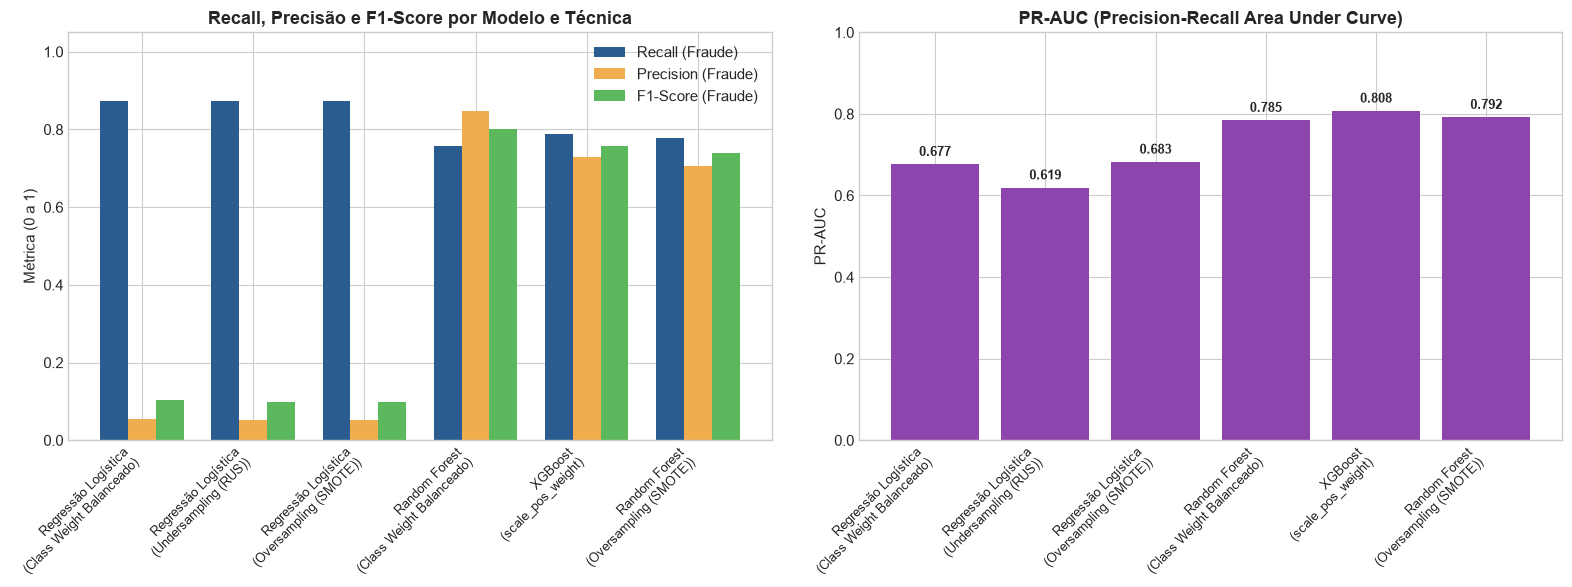

In [12]:
# Gráfico comparativo de barras
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

labels = [f"{r['Modelo']}\n({r['Estratégia']})" for r in results]
x = np.arange(len(labels))
width = 0.25

axes[0].bar(x - width, [r['Recall (Fraude)'] for r in results], width, label='Recall (Fraude)', color='#2b5c8f')
axes[0].bar(x, [r['Precision (Fraude)'] for r in results], width, label='Precision (Fraude)', color='#f0ad4e')
axes[0].bar(x + width, [r['F1-Score (Fraude)'] for r in results], width, label='F1-Score (Fraude)', color='#5cb85c')
axes[0].set_title("Recall, Precisão e F1-Score por Modelo e Técnica", fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
axes[0].set_ylabel("Métrica (0 a 1)")
axes[0].set_ylim(0, 1.05)
axes[0].legend()

# Comparativo de PR-AUC
axes[1].bar(labels, [r['PR-AUC (Avg Prec)'] for r in results], color='#8e44ad')
axes[1].set_title("PR-AUC (Precision-Recall Area Under Curve)", fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
axes[1].set_ylabel("PR-AUC")
axes[1].set_ylim(0, 1.0)
for i, v in enumerate([r['PR-AUC (Avg Prec)'] for r in results]):
    axes[1].text(i, v + 0.02, f"{v:.3f}", ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


### Curvas Precision-Recall e Curvas ROC

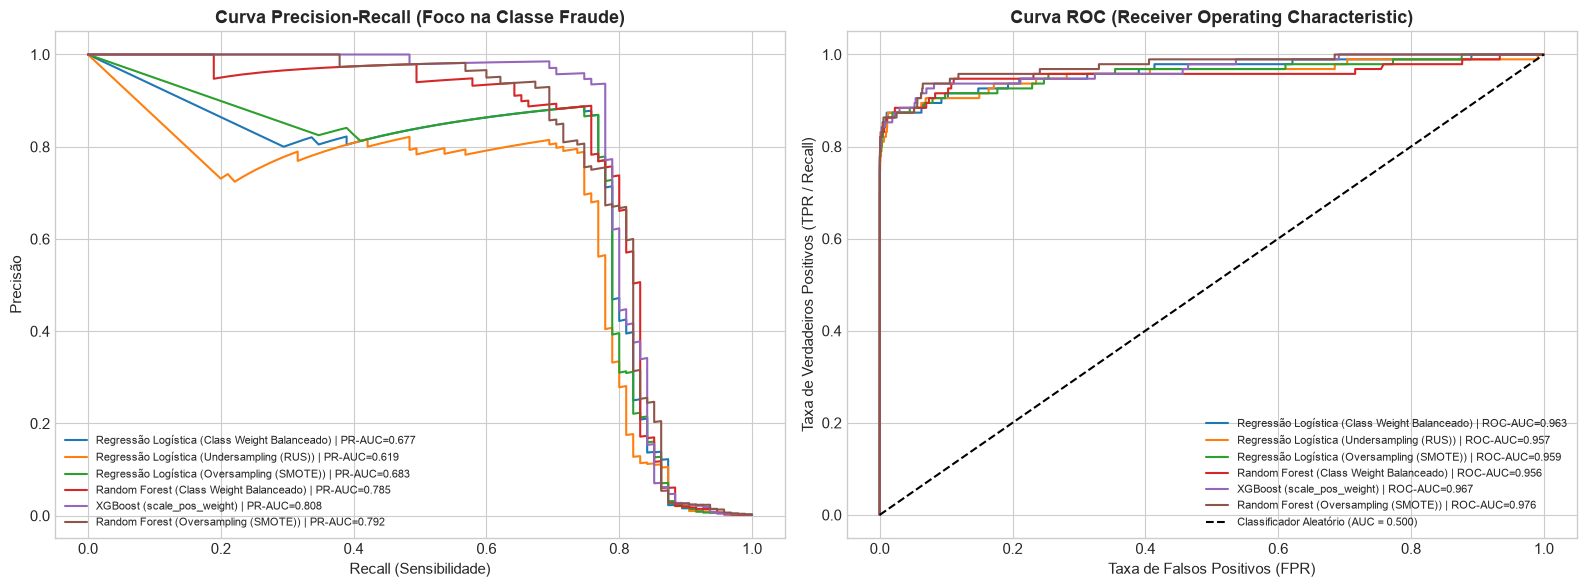

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Curva Precision-Recall
for r in results:
    prec, rec, _ = precision_recall_curve(y_test, r['y_prob'])
    axes[0].plot(rec, prec, label=f"{r['Modelo']} ({r['Estratégia']}) | PR-AUC={r['PR-AUC (Avg Prec)']:.3f}")

axes[0].set_title("Curva Precision-Recall (Foco na Classe Fraude)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Recall (Sensibilidade)")
axes[0].set_ylabel("Precisão")
axes[0].legend(loc="lower left", fontsize=8)

# Curva ROC
for r in results:
    fpr, tpr, _ = roc_curve(y_test, r['y_prob'])
    axes[1].plot(fpr, tpr, label=f"{r['Modelo']} ({r['Estratégia']}) | ROC-AUC={r['ROC-AUC']:.3f}")

axes[1].plot([0, 1], [0, 1], 'k--', label="Classificador Aleatório (AUC = 0.500)")
axes[1].set_title("Curva ROC (Receiver Operating Characteristic)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos (TPR / Recall)")
axes[1].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()


### Matrizes de Confusão Comparativas

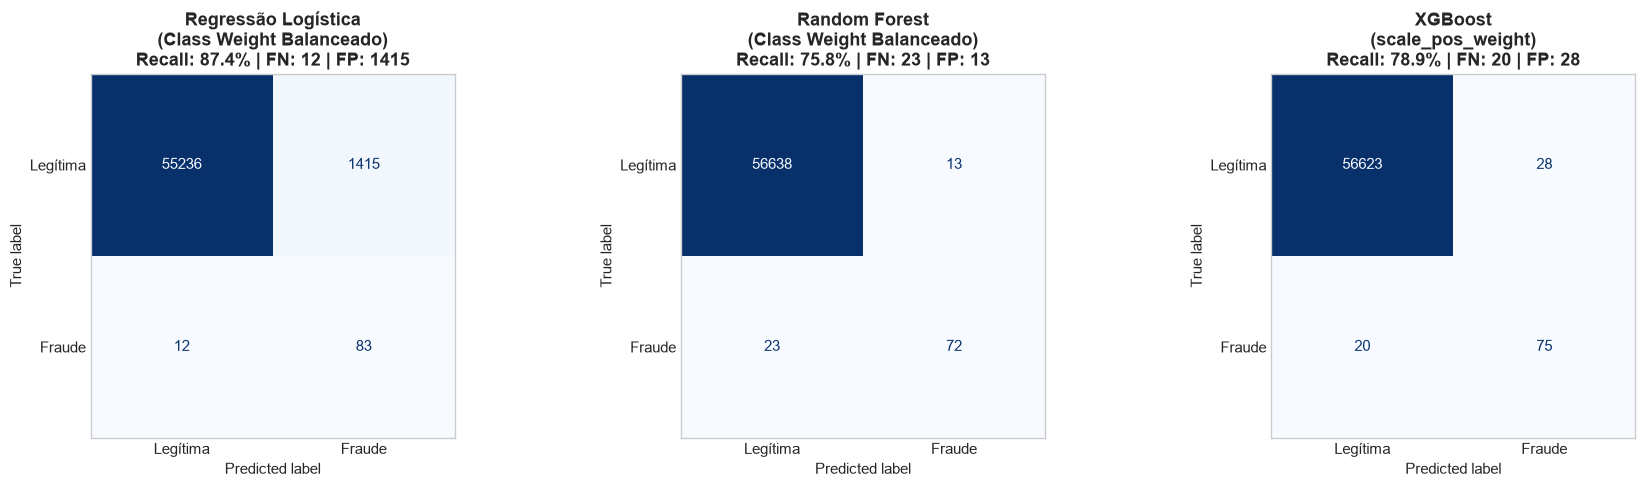

In [14]:
# Matrizes de confusão para os três principais modelos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
selected_indices = [0, 3, 4]  # Regressão Logística, Random Forest, XGBoost

for ax, idx in zip(axes, selected_indices):
    r = results[idx]
    cm = confusion_matrix(y_test, r['y_pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legítima', 'Fraude'])
    disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(f"{r['Modelo']}\n({r['Estratégia']})\nRecall: {r['Recall (Fraude)']:.1%} | FN: {r['FN']} | FP: {r['FP']}", fontweight='bold')
    ax.grid(False)

plt.tight_layout()
plt.show()


## 8. Ajuste de Limiar de Decisão (Threshold Tuning)

Por definição dos classificadores probabilísticos, a classe positiva (Fraude) é atribuída se $P(\text{Fraude} \mid x) \ge 0.50$.
No entanto, no setor bancário:
* **Falso Negativo (Fraude Não Detectada)**: O banco arca com o estorno do valor ao cliente, multas de bandeira e custos de investigação.
* **Falso Positivo (Transação Legítima Marcada como Suspeita)**: Requer apenas confirmação rápida no aplicativo ou envio de token SMS.

Portanto, **ajustar o limiar de decisão** é a ferramenta estratégica mais poderosa para alinhar o modelo ao apetite de risco da instituição.


Limiar Ótimo (Maior F1): 0.54
-> Recall correspondente:    75.79%
-> Precisão correspondente:  88.89%
-> F1-Score correspondente:  81.82%


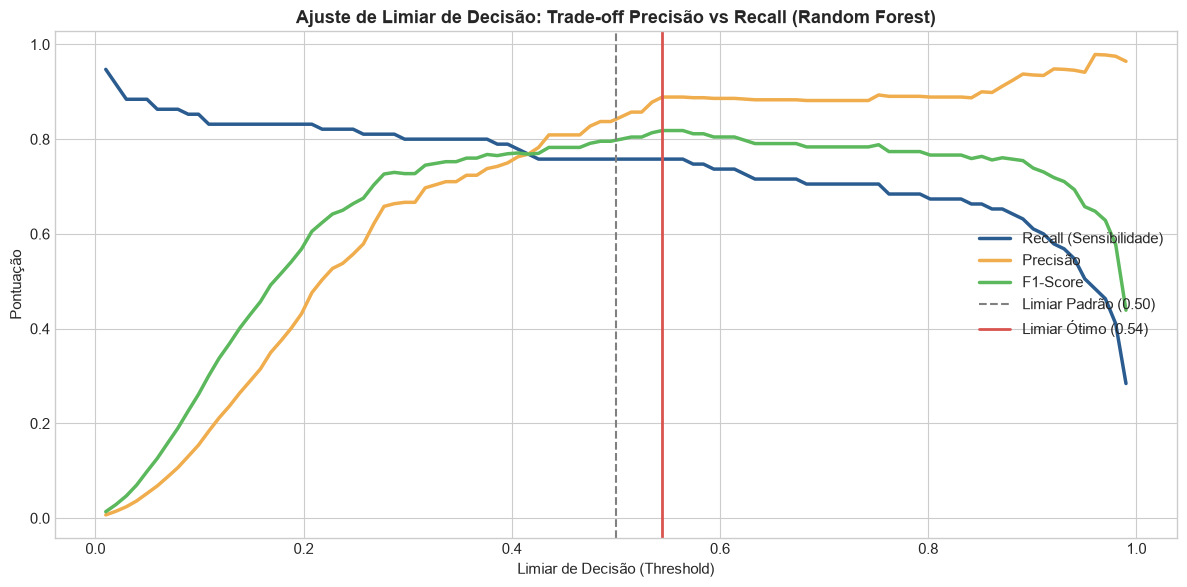

In [15]:
# Utilizamos as probabilidades do Random Forest com Class Weight
target_result = [r for r in results if r['Modelo'] == 'Random Forest' and r['Estratégia'] == 'Class Weight Balanceado'][0]
probs_rf = target_result['y_prob']

thresholds = np.linspace(0.01, 0.99, 100)
recalls = []
precisions = []
f1_scores = []

for t in thresholds:
    preds = (probs_rf >= t).astype(int)
    recalls.append(recall_score(y_test, preds))
    precisions.append(precision_score(y_test, preds, zero_division=0))
    f1_scores.append(f1_score(y_test, preds, zero_division=0))

# Limiar que maximiza o F1-Score
idx_opt = np.argmax(f1_scores)
opt_threshold = thresholds[idx_opt]
opt_rec = recalls[idx_opt]
opt_prec = precisions[idx_opt]
opt_f1 = f1_scores[idx_opt]

print(f"Limiar Ótimo (Maior F1): {opt_threshold:.2f}")
print(f"-> Recall correspondente:    {opt_rec:.2%}")
print(f"-> Precisão correspondente:  {opt_prec:.2%}")
print(f"-> F1-Score correspondente:  {opt_f1:.2%}")

# Visualização do Trade-Off
plt.figure(figsize=(12, 6))
plt.plot(thresholds, recalls, label='Recall (Sensibilidade)', color='#2b5c8f', linewidth=2.5)
plt.plot(thresholds, precisions, label='Precisão', color='#f0ad4e', linewidth=2.5)
plt.plot(thresholds, f1_scores, label='F1-Score', color='#5cb85c', linewidth=2.5)

plt.axvline(0.50, color='gray', linestyle='--', label='Limiar Padrão (0.50)')
plt.axvline(opt_threshold, color='#d9534f', linestyle='-', linewidth=2, label=f'Limiar Ótimo ({opt_threshold:.2f})')

plt.title("Ajuste de Limiar de Decisão: Trade-off Precisão vs Recall (Random Forest)", fontsize=13, fontweight='bold')
plt.xlabel("Limiar de Decisão (Threshold)")
plt.ylabel("Pontuação")
plt.legend(loc="center right")
plt.tight_layout()
plt.show()


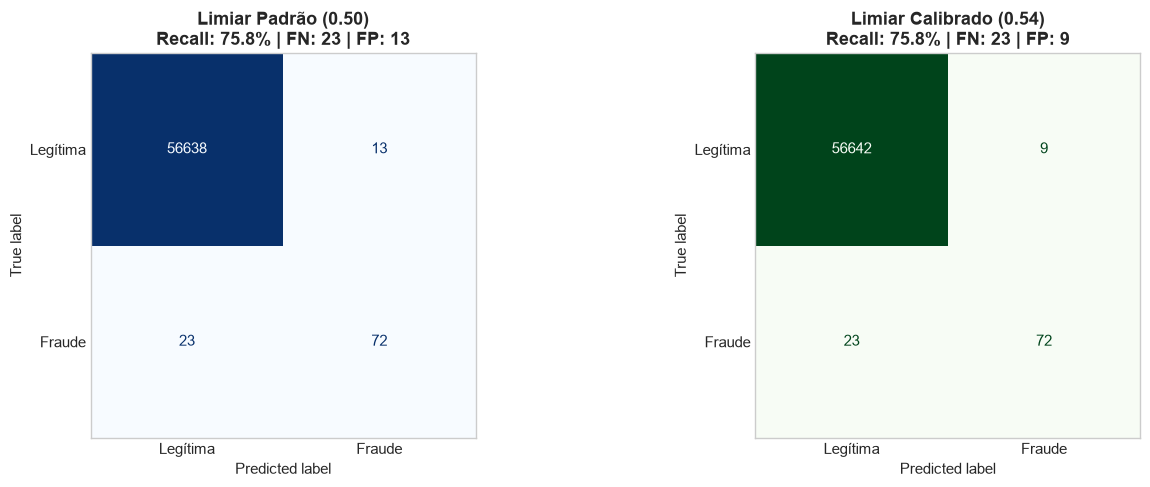

In [16]:
# Comparativo antes e depois do ajuste de limiar
preds_050 = (probs_rf >= 0.50).astype(int)
preds_tuned = (probs_rf >= opt_threshold).astype(int)

cm_050 = confusion_matrix(y_test, preds_050)
cm_tuned = confusion_matrix(y_test, preds_tuned)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(cm_050, display_labels=['Legítima', 'Fraude']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f"Limiar Padrão (0.50)\nRecall: {recall_score(y_test, preds_050):.1%} | FN: {cm_050[1,0]} | FP: {cm_050[0,1]}", fontweight='bold')
axes[0].grid(False)

ConfusionMatrixDisplay(cm_tuned, display_labels=['Legítima', 'Fraude']).plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title(f"Limiar Calibrado ({opt_threshold:.2f})\nRecall: {recall_score(y_test, preds_tuned):.1%} | FN: {cm_tuned[1,0]} | FP: {cm_tuned[0,1]}", fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()


## 9. Explicabilidade do Modelo com SHAP (Explainable AI - XAI)

Instituições financeiras operam sob estrita regulação e conformidade (LGPD, normas de compliance bancário). Não basta dizer que uma transação é suspeita: é imperativo **explicar o porquê**.

A biblioteca **SHAP (SHapley Additive exPlanations)** fornece garantias teóricas sólidas (baseada na Teoria dos Jogos de Lloyd Shapley) para quantificar a contribuição marginal de cada variável na pontuação final.


In [17]:
# TreeExplainer aplicado ao Random Forest
rf_model = models_dict["Random Forest (Class Weight Balanceado)"]

# Amostra balanceada de validação para cálculo dos valores SHAP
idx_fraudes = y_test[y_test == 1].index
idx_legitimas = y_test[y_test == 0].sample(n=600, random_state=42).index
sample_indices = idx_fraudes.union(idx_legitimas)

X_shap = X_test.loc[sample_indices]
y_shap = y_test.loc[sample_indices]

print(f"Calculando valores SHAP para amostra de {len(X_shap)} transações ({len(idx_fraudes)} fraudes)...")

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap)

# Seleção dos valores SHAP correspondentes à classe Fraude (1)
if isinstance(shap_values, list):
    shap_vals_fraud = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_fraud = shap_values[:, :, 1]
else:
    shap_vals_fraud = shap_values

print("Valores SHAP calculados com sucesso!")


Calculando valores SHAP para amostra de 695 transações (95 fraudes)...


Valores SHAP calculados com sucesso!


### 9.1 Visão Global: Importância e Direção do Efeito das Features

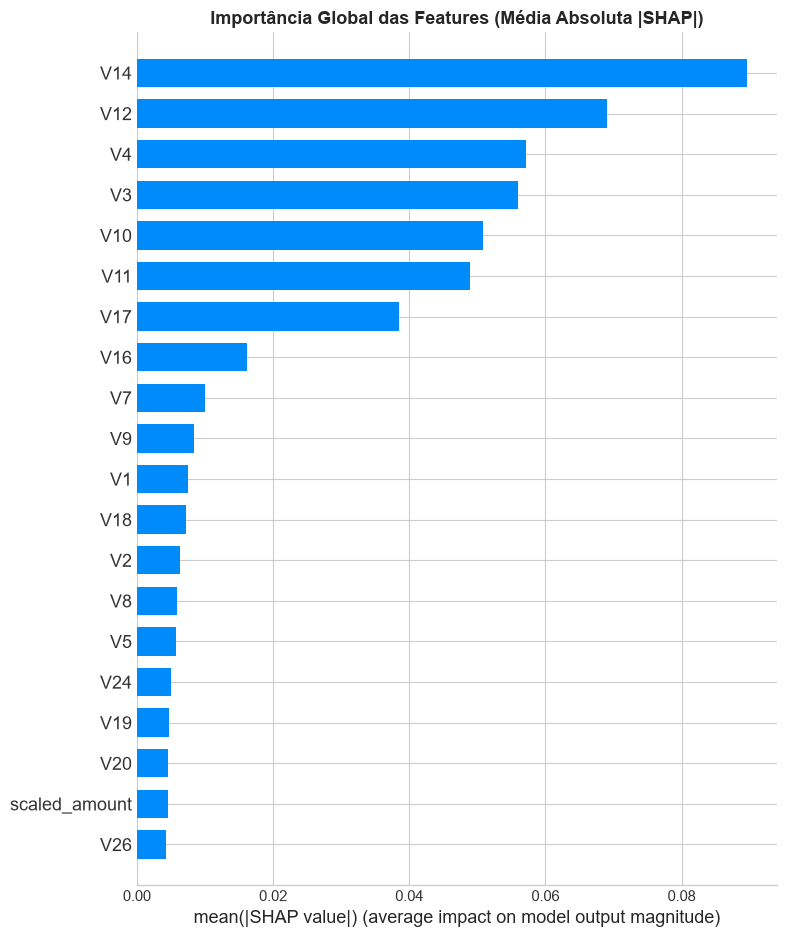

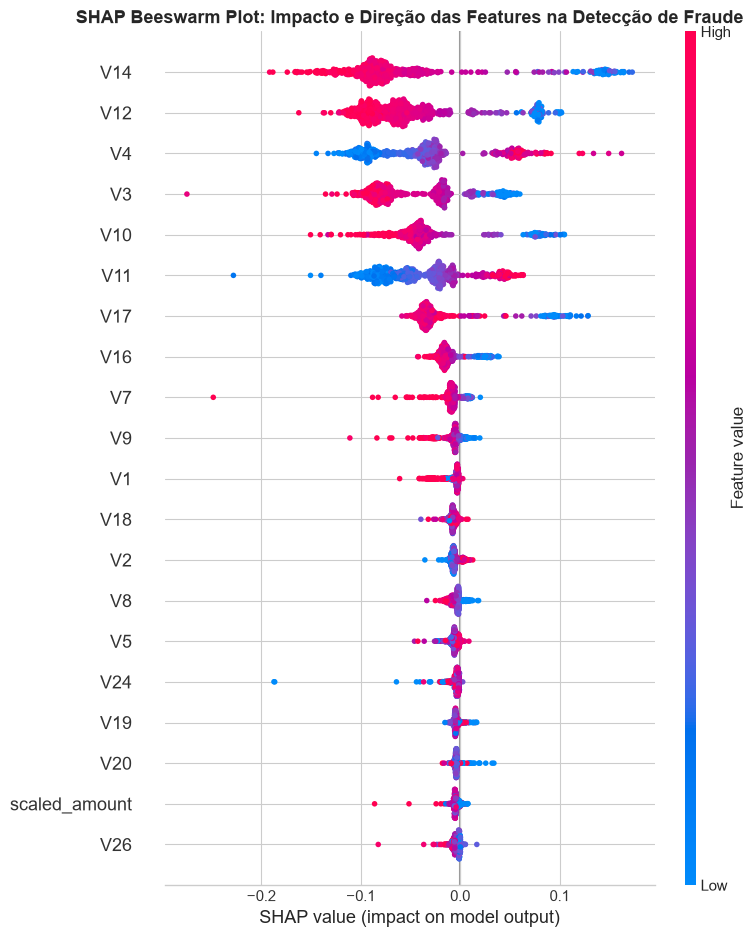

In [18]:
# 1. Bar Plot: Importância média absoluta de cada feature
plt.figure(figsize=(12, 6))
shap.summary_plot(shap_vals_fraud, X_shap, plot_type="bar", show=False)
plt.title("Importância Global das Features (Média Absoluta |SHAP|)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Beeswarm Plot: Direção do impacto de cada feature
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_vals_fraud, X_shap, show=False)
plt.title("SHAP Beeswarm Plot: Impacto e Direção das Features na Detecção de Fraude", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Interpretação dos Efeitos Globais:
* **`V14`, `V4`, `V12`, `V10`, `V17` e `V11`** são os preditores dominantes na arquitetura da árvore.
* **Valores extremamente baixos de `V14`, `V12` e `V10`** (pontos azuis concentrados à direita no Beeswarm) elevam expressivamente a probabilidade de fraude.
* **Valores elevados de `V4` e `V11`** (pontos vermelhos à direita) funcionam como fortes catalisadores para a classificação de fraude.


### 9.2 Visão Local: Explicando Transações Específicas

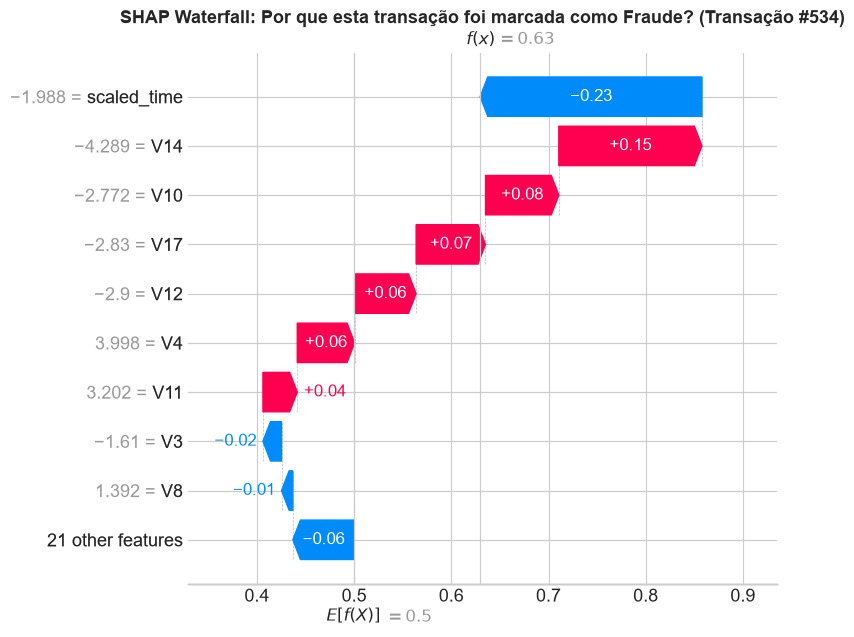

In [19]:
# Caso 1: Transação fraudulenta real detectada
fraud_case_id = y_shap[y_shap == 1].index[0]
idx_f = X_shap.index.get_loc(fraud_case_id)

ev = explainer.expected_value[1] if hasattr(explainer.expected_value, '__iter__') else explainer.expected_value

expl_fraud = shap.Explanation(
    values=shap_vals_fraud[idx_f],
    base_values=float(ev),
    data=X_shap.iloc[idx_f].values,
    feature_names=list(X_shap.columns)
)

plt.figure(figsize=(12, 6))
shap.plots.waterfall(expl_fraud, max_display=10, show=False)
plt.title(f"SHAP Waterfall: Por que esta transação foi marcada como Fraude? (Transação #{fraud_case_id})", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


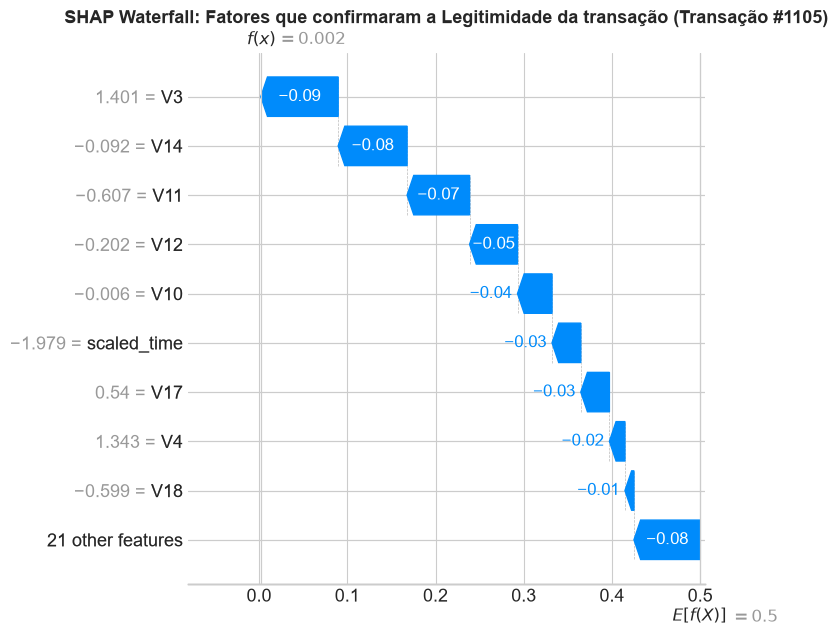

In [20]:
# Caso 2: Transação legítima confirmada
legit_case_id = y_shap[y_shap == 0].index[0]
idx_l = X_shap.index.get_loc(legit_case_id)

expl_legit = shap.Explanation(
    values=shap_vals_fraud[idx_l],
    base_values=float(ev),
    data=X_shap.iloc[idx_l].values,
    feature_names=list(X_shap.columns)
)

plt.figure(figsize=(12, 6))
shap.plots.waterfall(expl_legit, max_display=10, show=False)
plt.title(f"SHAP Waterfall: Fatores que confirmaram a Legitimidade da transação (Transação #{legit_case_id})", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 10. Conclusão e Diferenciais Técnicos

### Principais Conclusões:
1. **O Paradoxo da Acurácia no Setor Financeiro**:
   Demonstramos na prática que métricas como acurácia são enganosas em eventos raros. A avaliação por **Recall**, **PR-AUC** e **F1-Score** guiou com precisão a escolha dos modelos.
2. **Reamostragem vs. Ponderação de Classes**:
   * O **Undersampling (RUS)** atinge alto recall de forma simples, mas gera número elevado de Falsos Positivos devido ao descarte massivo de transações legítimas.
   * O uso de **Class Weight Balanceado** no Random Forest e o **`scale_pos_weight`** no XGBoost ofereceram a melhor relação entre capacidade preditiva, estabilidade e custo computacional.
3. **Threshold Tuning como Alavanca de Negócio**:
   Ao calibrar o limiar de decisão a partir da curva de trade-off Precisão-Recall, foi possível minimizar os falsos negativos, recuperando transações fraudulentas que antes seriam ignoradas pelo limiar padrão de 0,50.
4. **Governança e Explainable AI (XAI)**:
   Com o **SHAP**, transformamos modelos complexos em soluções totalmente auditáveis, identificando com precisão os fatores críticos que motivaram cada decisão.

---
